# Growing the pie: where Chow's neighbourhood coalition expanded, 2023 → 2026

**Question.** Between the 2023 by-election and the 2026 election, did Chow mainly *deepen* support in neighbourhoods that already favoured her, *extend* it into neighbouring areas with similar characteristics, or *reach* neighbourhood types that had been very different from her base? The blog section this supports describes her 2026 support as strongest in younger, rental-heavy, walkable neighbourhoods, in contrast with Bradford's strength in car-oriented, higher-income, detached-house neighbourhoods. What this notebook adds is **how that geographic coalition changed**, treating the "core-plus" idea (a coalition built from the centre outwards) as a proposition to test rather than assume.

**Scope and cautions.**
- The tract figures cover **mapped poll votes only** (the votes the City reports for polling subdivisions that have a map polygon), spread over 2021 census tracts by population-weighted areal interpolation. They are estimates of the geography of those votes, not observed tract ballots, and they omit advance and other unmapped ballots (§1 gives the coverage).
- The comparison is **Chow vs. Bailão (2023)** and **Chow vs. Bradford (2026)**.
- I describe a **coalition of neighbourhoods**. The 2021 census describes the same neighbourhoods in both elections, so what changes here is *support across neighbourhood types*, not the neighbourhoods themselves. Census percentages cannot identify who voted for Chow, converts or new voters, and I never multiply votes by census percentages.

In [1]:
import json
import re
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
REPO_ROOT = Path.cwd().resolve().parents[1]
ELECTION_DIR = REPO_ROOT / "data" / "election_results"
CLEAN_DIR = ELECTION_DIR / "2026-results-clean"
MAYOR_GPKG = CLEAN_DIR / "mayor_2023_2026_ct.gpkg"
COUNCIL_GPKG = CLEAN_DIR / "councillor_2026_ct.gpkg"       # only its `wards` layer is used (boundaries and names)
RAW_DIR = ELECTION_DIR / "2026-results-raw"
MAYOR_XLSX = RAW_DIR / "Poll_By_Poll_Mayor.xlsx"
ARCHIVE_2023 = (REPO_ROOT / "analysis" / "toronto_election_turnout" / "data" / "archive" / "elections"
                / "processed" / "municipal_2023_mayor")
CENSUS_META = REPO_ROOT / "src" / "routes" / "social-geography-and-the-mayoral-vote" / "data" / "meta.json"

PROJECTED_EPSG = 32617                    # UTM 17N (metres)
CITY_HALL_LONLAT = (-79.3841, 43.6534)    # Toronto City Hall / Nathan Phillips Square, used only to verify the distance field
SPECIAL_BUCKETS = (97, 98, 99)            # 2026 poll-by-poll subdivisions with no polygon
MAPPED_2023_TYPES = ("election_day", "special")
CANDIDATES = {2023: {"chow": "Chow Olivia", "opp": "Bailão Ana"}, 2026: {"chow": "Chow Olivia", "opp": "Bradford Brad"}}
OPP_SLUG = {2023: "bailao_ana", 2026: "bradford_brad"}

MIN_VALID_VOTES = 300                     # "small tract": fewer valid votes than this in either election
NEAR_TIE_PP = 2                           # "near tie": |margin| below this many points in either election

# Neighbourhood-type groups (by who led the head-to-head contest in each election)
GROUPS = ["Established support", "Newly leading", "Persistent opposition lead", "Reverse transition"]
TIE = "Exact tie in one election"          # a tract whose estimated Chow and opponent votes are exactly equal in 2023 or 2026
ALL_GROUPS = GROUPS + [TIE]
GROUP_COLOURS = {"Established support": "#54278f", "Newly leading": "#bcbddc", "Persistent opposition lead": "#238b45", "Reverse transition": "#e08214", TIE: "#737373"}
CHOW, OPP, OTHER = "#54278f", "#238b45", "#b5b5b5"       # Chow deep purple, main opponent green, everyone else grey
C23 = "#8c8c8c"

# Census characteristics: column -> (label with unit, scale to display). Income is shown as a tract rank, see §3.
PROFILE = {
    "hhtnrent_pct": ("Renter households (% of households)", 100), "dwtpsdet_pct": ("Single-detached dwellings (% of dwellings)", 100),
    "ihat_med__nc": ("Median household income, tract rank (0-100)", None), "agec2029_pct": ("Age 20-29 (% of residents)", 100),
    "agec065p_pct": ("Age 65+ (% of residents)", 100), "jwmdauto_pct": ("Commute by car (% of commuters)", 100),
    "walkbike": ("Commute by walking or cycling (% of commuters)", 100), "dist__nc": ("Distance from City Hall (km)", 1),
}
SECONDARY = {
    "jwmdtran_pct": ("Commute by transit (% of commuters)", 100), "popdsqkm__nc": ("Population density (thousand per km²)", 1e-3),
    "edcauniv_pct": ("University degree (% of adults)", 100), "occ_arts_pct": ("Arts, recreation and sports occupations (% of workers)", 100),
    "imstimmi_pct": ("Immigrants (% of residents)", 100), "vminvisi_pct": ("Visible minority (% of residents)", 100),
}
SHORT = {"hhtnrent_pct": "Renter households", "dwtpsdet_pct": "Single-detached dwellings", "ihat_med__nc": "Median household income (rank)", "agec2029_pct": "Age 20-29", "agec065p_pct": "Age 65+",
         "jwmdauto_pct": "Commute by car", "walkbike": "Commute by walking or cycling", "dist__nc": "Distance from City Hall", "jwmdtran_pct": "Commute by transit",
         "popdsqkm__nc": "Population density", "edcauniv_pct": "University degree", "occ_arts_pct": "Arts, recreation, sports occupations", "imstimmi_pct": "Immigrants", "vminvisi_pct": "Visible minority"}
LABEL_WARDS = [23, 18, 15, 2, 13, 19, 5]    # wards named on the map for orientation (names come from the ward layer)

DISTANCE_BANDS = [0, 5, 10, 15, 20, np.inf]
BAND_LABELS = ["0-5 km", "5-10 km", "10-15 km", "15-20 km", "20+ km"]
SECTORS = {"North": (337.5, 22.5), "Northeast": (22.5, 67.5), "East": (67.5, 112.5), "Southwest-West": (180, 292.5), "Northwest": (292.5, 337.5)}   # bearings clockwise from north
MIN_SECTOR_TRACTS = 15

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. The comparison, briefly

### 1.1 What the tract data cover

Official all-method totals and the mapped totals are rebuilt from the City's source files (2026 poll-by-poll workbook; archived 2023 poll data). The table is the reference for how far the tract analysis reaches.

In [3]:
mayor = gpd.read_file(MAYOR_GPKG, layer="mayor_ct")
wards = gpd.read_file(COUNCIL_GPKG, layer="wards")
ward_names = wards.set_index("ward")["ward_name"]

def parse_poll_by_poll(path):
    '''Long table (ward, sub, candidate, votes) from the City's poll-by-poll workbook (one sheet per ward).'''
    rows = []
    for sheet, x in tqdm(pd.read_excel(path, sheet_name=None, header=None).items(), desc="wards", leave=False):
        ward = int(sheet.split()[1]); subs = x.iloc[1, 1:-1].astype(int).tolist()
        body = x.iloc[3:-1]; body = body[body[0].notna()]
        for name, vals in zip(body[0], body.iloc[:, 1:-1].astype(float).values):
            rows.extend((ward, s, name.strip(), v) for s, v in zip(subs, vals))
    return pd.DataFrame(rows, columns=["ward", "sub", "candidate", "votes"])

src26 = parse_poll_by_poll(MAYOR_XLSX); src26["mapped"] = ~src26["sub"].isin(SPECIAL_BUCKETS)
polls23 = pd.read_csv(ARCHIVE_2023 / "turnout" / "toronto_municipal_2023_mayor_turnout_subdivisions.csv", usecols=["poll_id", "vote_type"])
cand23 = pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_candidates.csv").set_index("candidate_id")["candidate_name"]
src23 = pd.read_csv(ARCHIVE_2023 / "candidate_details" / "toronto_municipal_2023_mayor_poll_candidate_votes.csv").merge(polls23, on="poll_id")
src23["candidate"] = src23["candidate_id"].map(cand23); src23["votes"] = src23["candidate_vote_count"]; src23["mapped"] = src23["vote_type"].isin(MAPPED_2023_TYPES)
SRC = {2023: src23, 2026: src26}

def city_totals(year, mapped_only):
    d = SRC[year][SRC[year]["mapped"]] if mapped_only else SRC[year]; n = CANDIDATES[year]
    return pd.Series({"chow": d.loc[d.candidate == n["chow"], "votes"].sum(), "opp": d.loc[d.candidate == n["opp"], "votes"].sum(), "valid": d["votes"].sum()})

rows = []
for y in (2023, 2026):
    off, mp = city_totals(y, False), city_totals(y, True)
    lay = {"chow": mayor[f"mayor{y}_chow_olivia_votes"].sum(), "opp": mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"].sum(), "valid": mayor[f"mayor{y}_votes_candidates"].sum()}
    for label, s in (("official, all methods", off), ("tract layer, mapped votes", lay)):
        rows.append({"election": f"{y}: Chow vs. {CANDIDATES[y]['opp'].split()[0]}", "basis": label, "valid votes": s["valid"], "% of official": s["valid"] / off["valid"] * 100,
                     "Chow %": s["chow"] / s["valid"] * 100, "opponent %": s["opp"] / s["valid"] * 100, "leading pair %": (s["chow"] + s["opp"]) / s["valid"] * 100,
                     "Chow margin (pp)": (s["chow"] - s["opp"]) / s["valid"] * 100, "Chow share of pair %": s["chow"] / (s["chow"] + s["opp"]) * 100})
display(pd.DataFrame(rows).set_index(["election", "basis"]).round(1))

valid votes  % of official  Chow %  opponent %  leading pair %  Chow margin (pp)  Chow share of pair %
election                basis                                                                                                                            
2023: Chow vs. Bailão   official, all methods       724,638.00         100.00   37.20       32.50           69.60              4.70                 53.40
                        tract layer, mapped votes   566,398.00          78.20   34.40       37.60           71.90             -3.20                 47.80
2026: Chow vs. Bradford official, all methods       982,660.00         100.00   54.20       41.10           95.30             13.00                 56.80
                        tract layer, mapped votes   750,008.00          76.30   54.70       40.60           95.40             14.10                 57.40

**Scope note.** The tract layer holds **78.2%** of the official valid votes in 2023 and **76.3%** in 2026. In 2023 the unmapped votes are the advance and mail-in ballots, which favoured Chow strongly: officially she led Bailão by 4.7 points, but in the mapped votes she *trailed* him by 3.2. In 2026 the official and mapped margins are close (+13.0 vs. +14.1). So the 2023 "starting point" in this notebook is Chow's position among mapped poll votes, and "newly leading" below means newly leading **in mapped votes**; some of those neighbourhoods may already have favoured her in all-method terms in 2023, which the tract data cannot show.

### 1.2 Measures

In [4]:
t = mayor[["ctuid2021", "ward_dominant", "ward_dominant_share"]].copy()
for y in (2023, 2026):
    s = str(y)[2:]
    v, c, o = mayor[f"mayor{y}_votes_candidates"], mayor[f"mayor{y}_chow_olivia_votes"], mayor[f"mayor{y}_{OPP_SLUG[y]}_votes"]
    t[f"valid{s}"], t[f"chow_v{s}"], t[f"opp_v{s}"] = v, c, o
    t[f"chow{s}"], t[f"opp{s}"] = c / v * 100, o / v * 100
    t[f"lp{s}"] = (c + o) / v * 100
    t[f"margin{s}"] = t[f"chow{s}"] - t[f"opp{s}"]
    t[f"pair{s}"] = c / (c + o) * 100
t["d_chow_v"] = t.chow_v26 - t.chow_v23
t["volume_term"] = (t.valid26 - t.valid23) * t.chow23 / 100       # added votes if Chow's 2023 tract share had held
t["share_term"] = t.chow_v26 - t.chow23 / 100 * t.valid26         # added votes from the higher share of the 2026 votes
t["d_margin"], t["d_pair"] = t.margin26 - t.margin23, t.pair26 - t.pair23
t["big"] = (t.valid23 >= MIN_VALID_VOTES) & (t.valid26 >= MIN_VALID_VOTES)
t = t.merge(mayor.drop(columns=["geometry", "ward_dominant", "ward_dominant_share"] + [c for c in mayor.columns if c.startswith("mayor")] + ["area_km2"]), on="ctuid2021")
t["walkbike"] = t.jwmdwalk_pct + t.jwmdbike_pct
t["income_rank"] = t.ihat_med__nc.rank(pct=True) * 100
t = gpd.GeoDataFrame(t, geometry=mayor.geometry.values, crs=mayor.crs)
assert len(t) == 585 and np.allclose(t.volume_term + t.share_term, t.d_chow_v)
print("585 tracts. Measures: share and margin use all valid candidate votes; pair share = Chow / (Chow + main opponent); leading pair = Chow + main opponent.")

585 tracts. Measures: share and margin use all valid candidate votes; pair share = Chow / (Chow + main opponent); leading pair = Chow + main opponent.


## 2. Which neighbourhoods were added to her base?

A transparent classification by who **led the head-to-head contest** (Chow's signed margin over the main opponent above or below zero) in each election:

1. **Established support**: Chow led in both elections.
2. **Newly leading**: the main opponent led in 2023, Chow in 2026.
3. **Persistent opposition lead**: the main opponent led in both.
4. **Reverse transition**: Chow led in 2023, the opponent in 2026.

These are pairwise leads, not outright tract victories (other candidates' votes are ignored). Exact ties (estimated Chow votes equal to the opponent's in an election) are reported separately rather than assigned to a side.

In [5]:
lead = {s: np.sign(t[f"margin{s}"].round(9)) for s in ("23", "26")}
is_tie = (lead["23"] == 0) | (lead["26"] == 0)
print(f"Tracts with an exact tie (estimated Chow votes = opponent votes) in either election: {int(is_tie.sum())}; these four are kept out of the four groups and reported on their own:")
display(t.loc[is_tie, ["ctuid2021", "chow_v23", "opp_v23", "chow_v26", "opp_v26", "valid26"]].round(0).set_index("ctuid2021"))
t["group"] = np.select([is_tie, (lead["23"] > 0) & (lead["26"] > 0), (lead["23"] < 0) & (lead["26"] > 0), (lead["23"] < 0) & (lead["26"] < 0), (lead["23"] > 0) & (lead["26"] < 0)], [TIE] + GROUPS, "?")
assert (t.group != "?").all()

def pooled(df):
    o = {"tracts": len(df)}
    for s in ("23", "26"):
        V, C, O = df[f"valid{s}"].sum(), df[f"chow_v{s}"].sum(), df[f"opp_v{s}"].sum()
        o.update({f"valid{s}": V, f"chow_v{s}": C, f"chow{s}": C / V * 100, f"margin{s}": (C - O) / V * 100, f"pair{s}": C / (C + O) * 100})
    o["add_chow"] = o["chow_v26"] - o["chow_v23"]; o["volume_term"] = df.volume_term.sum(); o["share_term"] = df.share_term.sum(); o["g_valid"] = (o["valid26"] / o["valid23"] - 1) * 100
    return pd.Series(o)

G = pd.DataFrame({g: pooled(t[t.group == g]) for g in ALL_GROUPS}).T
G["share of Chow's votes 2023 %"] = G.chow_v23 / G.chow_v23.sum() * 100; G["share of Chow's votes 2026 %"] = G.chow_v26 / G.chow_v26.sum() * 100
G["share of her additional votes %"] = G.add_chow / G.add_chow.sum() * 100
show = G[["tracts", "chow23", "chow26", "margin23", "margin26", "pair23", "pair26", "add_chow", "share of her additional votes %", "share of Chow's votes 2023 %", "share of Chow's votes 2026 %", "g_valid"]]
display(show.rename(columns={"chow23": "Chow % 2023", "chow26": "Chow % 2026", "margin23": "margin 2023", "margin26": "margin 2026", "pair23": "pair % 2023", "pair26": "pair % 2026", "add_chow": "added Chow votes", "g_valid": "valid-vote growth %"}).round(1))
print("Tracts per group:", G.tracts.astype(int).to_dict(), "| citywide additional Chow votes:", f"{G.add_chow.sum():,.0f}")

Tracts with an exact tie (estimated Chow votes = opponent votes) in either election: 4; these four are kept out of the four groups and reported on their own:


,chow_v23,opp_v23,chow_v26,opp_v26,valid26
ctuid2021,,,,,
5350205.00,10.00,10.00,37.00,26.00,67.00
5350304.02,332.00,374.00,662.00,662.00,"1,379.00"
5350376.12,335.00,429.00,663.00,663.00,"1,419.00"
5350344.02,241.00,241.00,535.00,314.00,927.00


,tracts,Chow % 2023,Chow % 2026,margin 2023,margin 2026,pair % 2023,pair % 2026,added Chow votes,share of her additional votes %,share of Chow's votes 2023 %,share of Chow's votes 2026 %,valid-vote growth %
Established support,256.00,45.80,65.70,17.70,36.20,62.00,69.00,"108,917.00",50.50,57.20,53.70,37.80
Newly leading,146.00,30.60,53.30,-8.60,11.60,43.80,56.10,"57,525.00",26.70,22.50,24.70,32.60
Persistent opposition lead,177.00,21.70,39.30,-27.70,-17.30,30.60,41.00,"47,869.00",22.20,19.70,21.00,24.70
Reverse transition,2.00,32.00,44.50,5.20,-1.10,54.40,49.40,415.00,0.20,0.20,0.20,72.80
Exact tie in one election,4.00,32.40,50.00,-4.80,6.10,46.60,53.30,979.00,0.50,0.50,0.50,34.00


Tracts per group: {'Established support': 256, 'Newly leading': 146, 'Persistent opposition lead': 177, 'Reverse transition': 2, 'Exact tie in one election': 4} | citywide additional Chow votes: 215,705


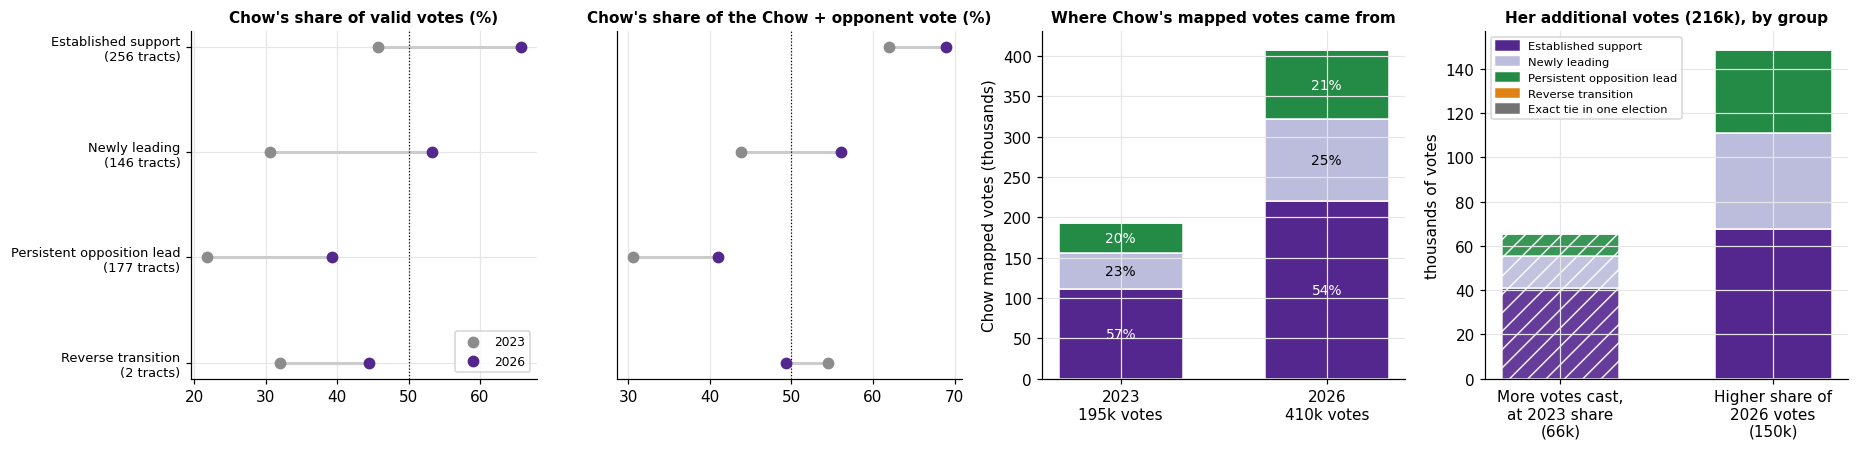

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.05, 1.05]})
y = np.arange(len(GROUPS))[::-1]   # dumbbells: the four groups only (the 4 tied tracts are too few)
for a, (c23, c26, ttl, ref) in zip(ax[:2], (("chow23", "chow26", "Chow's share of valid votes (%)", 50), ("pair23", "pair26", "Chow's share of the Chow + opponent vote (%)", 50))):
    Gd = G.loc[GROUPS]; a.hlines(y, Gd[c23], Gd[c26], color="#cccccc", lw=2); a.scatter(Gd[c23], y, color=C23, s=45, zorder=3, label="2023"); a.scatter(Gd[c26], y, color=CHOW, s=45, zorder=3, label="2026")
    a.axvline(ref, color="k", ls=":", lw=.8); a.set(title=ttl); a.set_yticks(y); a.set_yticklabels([f"{g}\n({int(G.loc[g, 'tracts'])} tracts)" for g in GROUPS], fontsize=8.5) if a is ax[0] else a.set_yticks([])
ax[0].legend(fontsize=8, loc="lower right")
a = ax[2]; b23 = b26 = 0.0
for g in ALL_GROUPS:
    v23, v26 = G.loc[g, "chow_v23"] / 1e3, G.loc[g, "chow_v26"] / 1e3
    a.bar(0, v23, bottom=b23, color=GROUP_COLOURS[g], width=.6, edgecolor="white"); a.bar(1, v26, bottom=b26, color=GROUP_COLOURS[g], width=.6, edgecolor="white")
    light = g in ("Newly leading",)
    if v23 > 8: a.text(0, b23 + v23 / 2, f"{v23 / (G.chow_v23.sum() / 1e3) * 100:.0f}%", ha="center", va="center", fontsize=9, color="black" if light else "white")
    if v26 > 8: a.text(1, b26 + v26 / 2, f"{v26 / (G.chow_v26.sum() / 1e3) * 100:.0f}%", ha="center", va="center", fontsize=9, color="black" if light else "white")
    b23 += v23; b26 += v26
a.set_xticks([0, 1]); a.set_xticklabels([f"2023\n{G.chow_v23.sum() / 1e3:.0f}k votes", f"2026\n{G.chow_v26.sum() / 1e3:.0f}k votes"]); a.set(title="Where Chow's mapped votes came from", ylabel="Chow mapped votes (thousands)")
a = ax[3]; bottom = 0
for g in ALL_GROUPS:
    a.bar(0, G.loc[g, "volume_term"] / 1e3, bottom=bottom, color=GROUP_COLOURS[g], width=.55, edgecolor="white", hatch="//", alpha=.9)
    bottom += G.loc[g, "volume_term"] / 1e3
bottom = 0
for g in ALL_GROUPS:
    a.bar(1, G.loc[g, "share_term"] / 1e3, bottom=bottom, color=GROUP_COLOURS[g], width=.55, edgecolor="white"); bottom += G.loc[g, "share_term"] / 1e3
a.set_xticks([0, 1]); a.set_xticklabels([f"More votes cast,\nat 2023 share\n({G.volume_term.sum() / 1e3:.0f}k)", f"Higher share of\n2026 votes\n({G.share_term.sum() / 1e3:.0f}k)"]); a.set(title="Her additional votes (216k), by group", ylabel="thousands of votes")
ax[3].legend(handles=[Patch(color=GROUP_COLOURS[g], label=g) for g in ALL_GROUPS], fontsize=7.5, loc="upper left")
plt.tight_layout(); plt.show()

**Reading the classification.** Chow led the head-to-head contest in **256 tracts in both elections** (established support), moved from trailing to leading in **146** (newly leading), trailed in **177** both times (persistent opposition lead), and went from leading to trailing in only **2**. Four more tracts have an exact tie in one election and are shown separately. (The first notebook's 148 and 179 counted two tied tracts on each side; with ties set aside it is 146 and 177.)

- **Established support:** Chow's share rose from 45.8% to 65.7% and her margin from +17.7 to +36.2 points; she added 108,917 mapped votes, **50.5% of her additional votes**. Her votes here fell from 57% to 54% of her mapped total.
- **Newly leading:** share 30.6% → 53.3%, margin −8.6 → +11.6, pair share 43.8% → 56.1%; **57,525 added votes (26.7%)**; these tracts' part of her mapped votes rose from 22.5% to 24.7%.
- **Persistent opposition lead:** share 21.7% → 39.3% and margin −27.7 → −17.3, so she gained about 18 points without overtaking the opponent; **47,869 added votes (22.2%)**.

So her gain is territorial *and* a deepening: half of the added votes were in places she already led, a quarter in places she newly led, and a fifth where she still trailed. These are votes added *in* those areas, not votes from existing supporters or conversions; the right-hand panel adds that overall voting volume grew too (valid mapped votes +37.8% in established tracts, +32.6% in newly leading, +24.7% in persistent-opposition tracts), and of her 216k additional votes about 66k correspond to more votes cast at her 2023 share and 150k to a higher share. Against the main opponent *within the pair*, her gain is larger in the newly leading tracts than in the others (median tract change in pair share +11.4 points, vs. +6.9 established and +9.8 persistent opposition).

### 2.1 How sensitive is the classification?

Two quick checks: dropping **near-ties** (|margin| under 2 points in either election, where a small shift in the underlying estimate could flip a tract) and dropping **small tracts** (under 300 valid votes in either election).

In [7]:
near = (t.margin23.abs() < NEAR_TIE_PP) | (t.margin26.abs() < NEAR_TIE_PP)
variants = {"all tracts": t.index == t.index, f"drop near-ties ({int(near.sum())})": ~near, f"drop small tracts ({int((~t.big).sum())})": t.big, "drop both": ~near & t.big}
rows = []
for name, m in variants.items():
    d = t[m]; tot_add = d.chow_v26.sum() - d.chow_v23.sum()
    r = {"variant": name, "tracts": len(d)}
    for g in ALL_GROUPS:
        r[f"{g}: tracts"] = int((d.group == g).sum())
    for g in ("Established support", "Newly leading"):
        dd = d[d.group == g]; r[f"{g}: % of added votes"] = (dd.chow_v26.sum() - dd.chow_v23.sum()) / tot_add * 100
    rows.append(r)
display(pd.DataFrame(rows).set_index("variant").round(1))
print(f"Tracts that are near-ties in the newly leading group: {int(((t.group == 'Newly leading') & near).sum())} of {int((t.group == 'Newly leading').sum())}; "
      f"in the reverse-transition group: {int(((t.group == 'Reverse transition') & near).sum())} of {int((t.group == 'Reverse transition').sum())}")

,tracts,Established support: tracts,Newly leading: tracts,Persistent opposition lead: tracts,Reverse transition: tracts,Exact tie in one election: tracts,Established support: % of added votes,Newly leading: % of added votes
variant,,,,,,,,
all tracts,585,256,146,177,2,4,50.50,26.70
drop near-ties (77),508,234,113,160,1,0,53.50,24.10
drop small tracts (28),557,240,143,169,2,3,50.40,26.80
drop both,482,218,110,153,1,0,53.40,24.20


Tracts that are near-ties in the newly leading group: 33 of 146; in the reverse-transition group: 1 of 2


The classification is stable to small tracts (dropping the 28 smallest changes the newly leading count from 146 to 143 and her share of added votes there from 26.7% to 26.8%). It is more sensitive to near-ties: 33 of the 146 newly leading tracts (23%) were within two points of an even contest in at least one election, and removing all near-tied tracts leaves 113 newly leading tracts supplying 24.1% of her added votes (established support: 53.5%). The headline reading survives (roughly half of added votes in established areas, about a quarter in newly leading ones), but the *boundary* of the newly leading group is soft and individual tracts should not be over-read. The two reverse-transition tracts are too few to profile.

## 3. What kinds of neighbourhoods were added?

The main comparison: **newly leading** tracts against **established support** and **persistent opposition**. Each dot below is one tract; the large marker is the group median and the bar spans the middle half (equal-tract medians, so every tract counts once). Orange diamonds are the two reverse-transition tracts, shown only for completeness and not as a sample.

**Definitions checked.** All shares are 2021 census shares of the universes named below. Walking and cycling share one denominator (commuters) and are combined. **Distance from City Hall** (`dist__nc`) is checked directly: it correlates r = 1.00 with a straight-line distance from City Hall to each tract's centroid that I computed independently, differing by about 0.4 km on average. Median household income is shown as a **tract rank** (0 to 100) because the repository does not document the income reference year or price basis, so dollar levels are not interpreted; "median" values for a group are medians of tract ranks, never the median income of the combined area.

In [8]:
meta = json.load(open(CENSUS_META)); by_id = {v["id"]: v for v in meta["variables"]}; by_nom = {v["nom"]: v for v in meta["variables"] if v.get("nom")}
cp = gpd.GeoSeries.from_xy([CITY_HALL_LONLAT[0]], [CITY_HALL_LONLAT[1]], crs=4326).to_crs(PROJECTED_EPSG).iloc[0]
cent = t.to_crs(PROJECTED_EPSG).geometry.centroid
t["dx"], t["dy"] = cent.x - cp.x, cent.y - cp.y
own_km = np.hypot(t.dx, t.dy) / 1000
print(f"Distance field check: r = {np.corrcoef(own_km, t.dist__nc)[0, 1]:.4f}; mean |difference| = {np.abs(own_km - t.dist__nc).mean():.2f} km (field is {t.dist__nc.mean() / own_km.mean() - 1:+.1%} larger on average)")
rows = []
for col, (label, scale) in {**PROFILE, **SECONDARY}.items():
    v = by_id.get(col) or by_nom.get(col)
    if col == "walkbike":
        assert by_id["jwmdwalk_pct"]["den"] == by_id["jwmdbike_pct"]["den"]; uni = by_id["jwmdwalk_pct"]["den_label"] + " (walk + bike)"
    else:
        uni = v.get("den_label") if v.get("kind") == "pct" else (v.get("unit") or "")
    rows.append({"measure": label, "census column": col, "universe / unit (from metadata)": uni, "missing tracts": int(t[col].isna().sum())})
display(pd.DataFrame(rows).set_index("measure"))

Distance field check: r = 1.0000; mean |difference| = 0.44 km (field is +4.1% larger on average)


,census column,universe / unit (from metadata),missing tracts
measure,,,
Renter households (% of households),hhtnrent_pct,Dwellings - Tenure - Total,2
Single-detached dwellings (% of dwellings),dwtpsdet_pct,Dwellings - Type - Total,0
"Median household income, tract rank (0-100)",ihat_med__nc,dollars,2
Age 20-29 (% of residents),agec2029_pct,Population by Age - Total,0
Age 65+ (% of residents),agec065p_pct,Population by Age - Total,0
Commute by car (% of commuters),jwmdauto_pct,Commute - Total,2
Commute by walking or cycling (% of commuters),walkbike,Commute - Total (walk + bike),2
Distance from City Hall (km),dist__nc,km,0
Commute by transit (% of commuters),jwmdtran_pct,Commute - Total,2


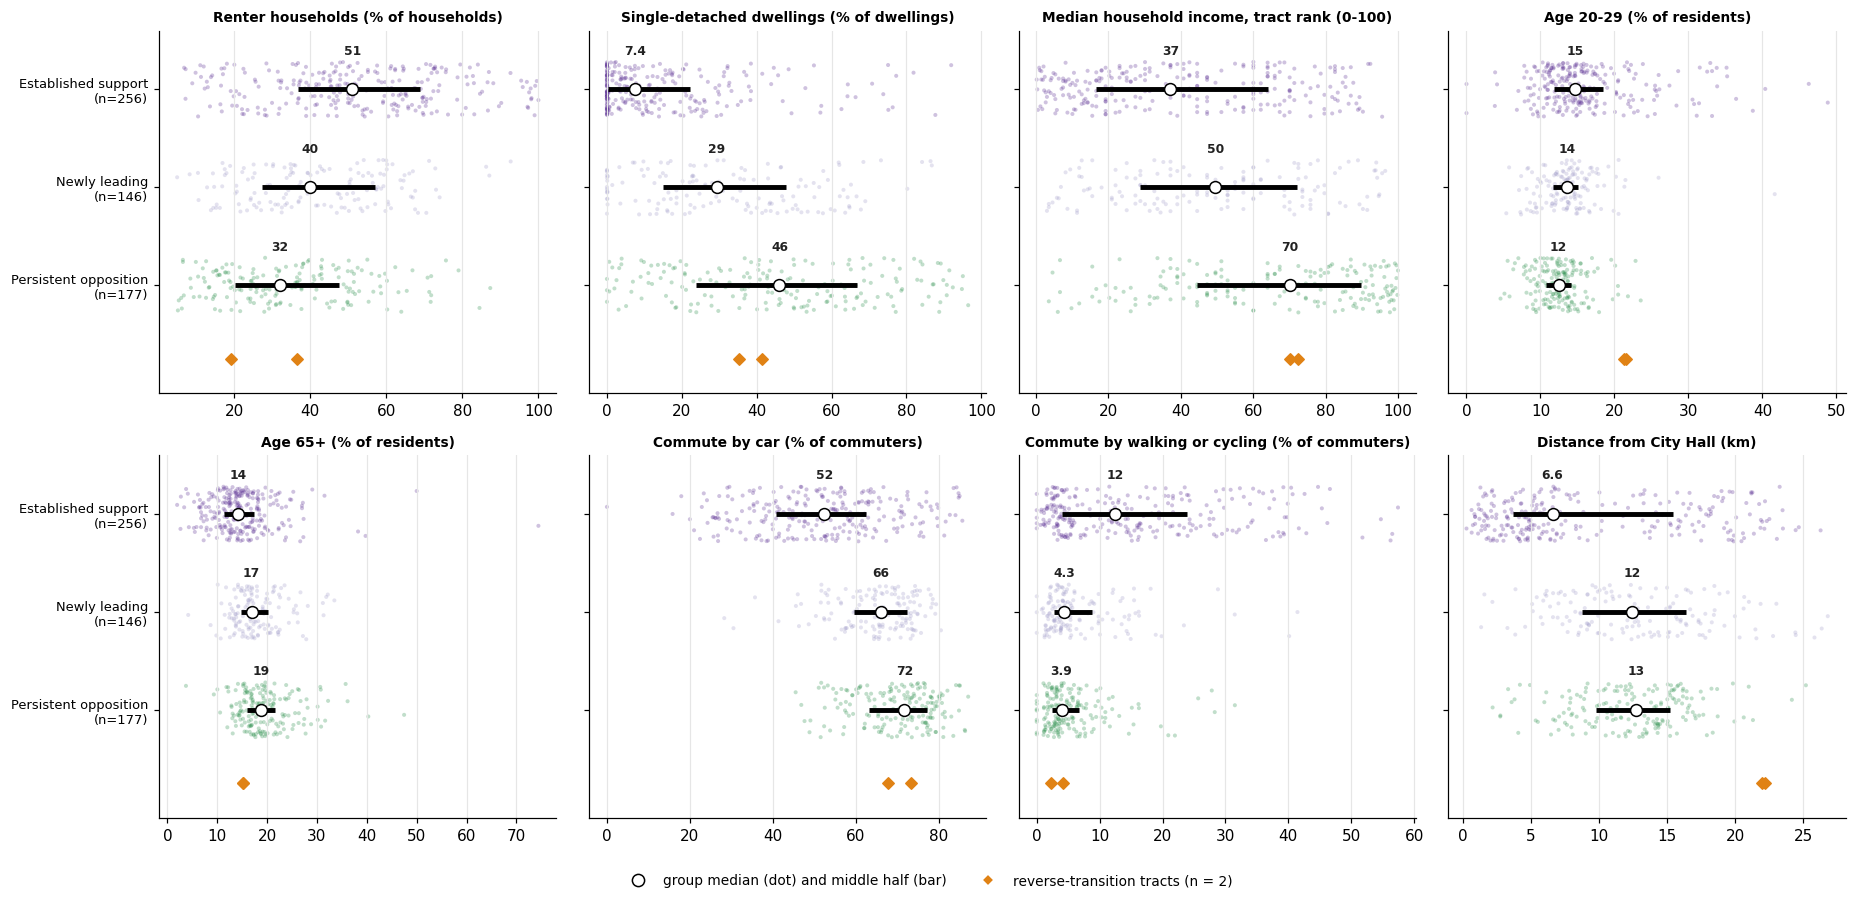

In [9]:
rng = np.random.default_rng(7)
def display_values(col, scale):
    if col == "ihat_med__nc": return t["income_rank"]
    return t[col] * scale

main = ["Established support", "Newly leading", "Persistent opposition lead"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2))
for a, (col, (label, scale)) in zip(axes.ravel(), PROFILE.items()):
    vals = display_values(col, scale)
    for i, g in enumerate(main):
        v = vals[t.group == g].dropna(); yy = 2 - i
        a.scatter(v, yy + rng.uniform(-.28, .28, len(v)), s=7, alpha=.28, color=GROUP_COLOURS[g] if g != "Newly leading" else "#9e9ac8", edgecolor="none")
        q1, med, q3 = v.quantile([.25, .5, .75]); a.plot([q1, q3], [yy, yy], color="k", lw=3.2, solid_capstyle="butt", zorder=3); a.scatter([med], [yy], color="white", edgecolor="k", s=60, zorder=4)
        a.text(med, yy + .36, f"{med:.0f}" if med >= 10 else f"{med:.1f}", ha="center", fontsize=8, color="#222", fontweight="bold")
    rev = vals[t.group == "Reverse transition"].dropna(); a.scatter(rev, [-.75] * len(rev), marker="D", color=GROUP_COLOURS["Reverse transition"], s=28, zorder=3)
    short = {"Established support": "Established support", "Newly leading": "Newly leading", "Persistent opposition lead": "Persistent opposition"}
    a.set_yticks([2, 1, 0]); a.set_yticklabels([f"{short[g]}\n(n={int((t.group == g).sum())})" for g in main] if a in axes[:, 0] else [], fontsize=8.5)
    a.set_title(label, fontsize=9); a.set_ylim(-1.1, 2.6); a.grid(False, axis="y")
fig.legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor="white", markeredgecolor="k", ms=8, label="group median (dot) and middle half (bar)"),
                    Line2D([], [], marker="D", color="w", markerfacecolor=GROUP_COLOURS["Reverse transition"], ms=6, label="reverse-transition tracts (n = 2)")], loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

**Reading the distributions.** The newly leading tracts do not look like the established core: they have a median of 12.4 km from City Hall (core: 6.6 km), 66% car commuters (core: 52%) and 4.3% walking or cycling (core: 12.4%); on those three they resemble the persistent-opposition areas (12.7 km, 72%, 3.9%). On housing, tenure and income they sit between: renters 40% (core 51%, opposition 32%), single-detached 29% (7% and 46%), income rank 50 (37 and 70). On age the groups differ less (age 20-29: 15%, 14% and 12%; age 65+: 14%, 17% and 19%). The wide bars show that the groups overlap a lot, and the newly leading group is the most spread out on income rank and detached housing, with its centre between the other two.

### 3.1 Do newly leading tracts resemble the established base or the opposition areas?

For every characteristic (primary and secondary), the three groups' **medians** expressed in standard deviations from the citywide median tract, so that very different units are comparable. A dot for the newly leading group sitting between the other two means those tracts are intermediate on that characteristic. The closing panel repeats the comparison with medians weighted by 2026 valid votes.

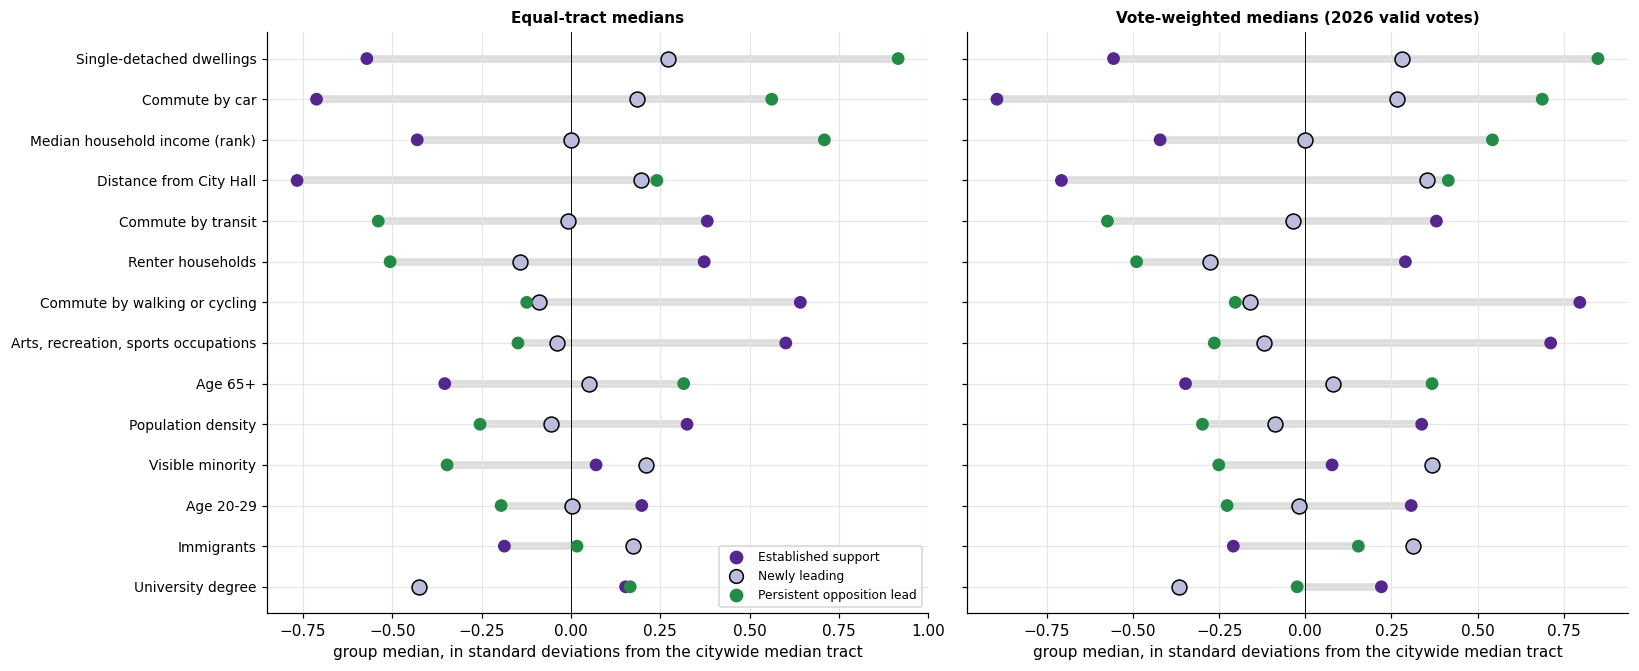

Characteristics where the newly leading median lies between the established and persistent-opposition medians: 11 of 14 (vote-weighted: 11 of 14)
Position of newly leading tracts between the two other groups (0 = like established support, 1 = like persistent opposition), where the two differ by > 0.3 SD:
label         Visible minority  Median household income (rank)  Commute by transit  Age 20-29  Single-detached dwellings  Renter households  Age 65+  Population density  Commute by car  Arts, recreation, sports occupations  Commute by walking or cycling  Distance from City Hall
new_position             -0.34                            0.38                0.42       0.50                       0.57               0.59     0.61                0.66            0.70                                  0.86                           0.96                     0.96


In [10]:
def wmedian(x, w):
    o = np.argsort(x.values); x, w = x.values[o], w.values[o]; c = np.cumsum(w) / w.sum(); return x[np.searchsorted(c, .5)]

allv = {**PROFILE, **SECONDARY}; rows = []
for col, (label, scale) in allv.items():
    v = display_values(col, scale); ok = v.notna(); sd, cm = v[ok].std(), v[ok].median(); r = {"col": col, "label": SHORT[col]}
    for g in main:
        m = (t.group == g) & ok
        r[g], r[g + " (w)"] = (v[m].median() - cm) / sd, (wmedian(v[m], t.valid26[m]) - (wmedian(v[ok], t.valid26[ok]))) / sd
    rows.append(r)
P = pd.DataFrame(rows).set_index("col"); P["gap"] = (P["Persistent opposition lead"] - P["Established support"]).abs()
P["new_between"] = P["Newly leading"].between(P[["Established support", "Persistent opposition lead"]].min(axis=1), P[["Established support", "Persistent opposition lead"]].max(axis=1))
P["new_between_w"] = P["Newly leading (w)"].between(P[["Established support (w)", "Persistent opposition lead (w)"]].min(axis=1), P[["Established support (w)", "Persistent opposition lead (w)"]].max(axis=1))
P["new_position"] = (P["Newly leading"] - P["Established support"]) / (P["Persistent opposition lead"] - P["Established support"])   # 0 = like established, 1 = like opposition
P = P.sort_values("gap")
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2), sharey=True)
for a, suffix, ttl in zip(ax, ("", " (w)"), ("Equal-tract medians", "Vote-weighted medians (2026 valid votes)")):
    for yy, (col, r) in enumerate(P.iterrows()):
        a.hlines(yy, min(r["Established support" + suffix], r["Persistent opposition lead" + suffix]), max(r["Established support" + suffix], r["Persistent opposition lead" + suffix]), color="#dddddd", lw=5, zorder=1)
        for g in main: a.scatter(r[g + suffix], yy, s=70 if g != "Newly leading" else 95, color=GROUP_COLOURS[g], edgecolor="k" if g == "Newly leading" else "none", zorder=3)
    a.axvline(0, color="k", lw=.6); a.set_yticks(range(len(P))); a.set_yticklabels(P.label, fontsize=9); a.set(title=ttl, xlabel="group median, in standard deviations from the citywide median tract")
ax[0].legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor=GROUP_COLOURS[g], markeredgecolor="k" if g == "Newly leading" else "none", ms=9, label=g) for g in main], fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print(f"Characteristics where the newly leading median lies between the established and persistent-opposition medians: {int(P.new_between.sum())} of {len(P)} (vote-weighted: {int(P.new_between_w.sum())} of {len(P)})")
print("Position of newly leading tracts between the two other groups (0 = like established support, 1 = like persistent opposition), where the two differ by > 0.3 SD:")
print(P[P.gap > .3].sort_values("new_position")[["label", "new_position"]].assign(new_position=lambda d: d.new_position.round(2)).set_index("label").T.to_string())

**Between, but not in the middle on every measure.** On 11 of the 14 characteristics (unchanged when weighting by votes) the newly leading median lies between the established and persistent-opposition medians. Where it lies varies: on walking/cycling (0.96 of the way from established to opposition), distance (0.96), arts occupations (0.86) and car commuting (0.70) the newly leading tracts are close to the opposition areas; on income (0.38), transit (0.42), age 20-29 (0.50), detached housing (0.57), renters (0.59) and age 65+ (0.61) they are roughly in the middle; and on **university education, immigrant share and visible-minority share they lie outside both**: they have the lowest university share of the three groups (median 32% vs. 41-42%) and the highest immigrant (49% vs. 44% and 47%) and visible-minority (58% vs. 55% and 45%) shares. So they are intermediate in housing, income and age, close to the opposition areas in travel behaviour and distance, and different from both in education and migration background. I do not interpret the last as an explanation of how those neighbourhoods voted.

In [11]:
med = pd.DataFrame({g: pd.Series({SHORT[c]: display_values(c, PROFILE[c][1])[t.group == g].median() for c in PROFILE}) for g in main})
med["newly leading minus established"] = med["Newly leading"] - med["Established support"]; med["opposition minus established"] = med["Persistent opposition lead"] - med["Established support"]
print("Group medians (equal-tract), in the units of the panels above:"); display(med.round(1))
med2 = pd.DataFrame({g: pd.Series({SHORT[c]: display_values(c, SECONDARY[c][1])[t.group == g].median() for c in SECONDARY}) for g in main})
print("Secondary characteristics, group medians (equal-tract), same units as the labels in section 3:"); display(med2.round(1))
within = t.groupby("group")[["d_pair", "pair23", "pair26"]].median().loc[main]
print("Median tract change in Chow's share of the pair, 2023 → 2026 (pp):", within.d_pair.round(1).to_dict())

Group medians (equal-tract), in the units of the panels above:


,Established support,Newly leading,Persistent opposition lead,newly leading minus established,opposition minus established
Renter households,51.00,39.90,32.00,-11.10,-19.00
Single-detached dwellings,7.40,29.40,46.10,21.90,38.70
Median household income (rank),37.10,49.60,70.10,12.40,32.90
Age 20-29,14.70,13.60,12.50,-1.10,-2.30
Age 65+,14.10,16.90,18.70,2.80,4.60
Commute by car,52.50,66.00,71.70,13.50,19.20
Commute by walking or cycling,12.40,4.30,3.90,-8.10,-8.50
Distance from City Hall,6.60,12.40,12.70,5.80,6.10


Secondary characteristics, group medians (equal-tract), same units as the labels in section 3:


,Established support,Newly leading,Persistent opposition lead
Commute by transit,27.90,24.50,19.90
Population density,8.30,5.00,3.20
University degree,41.40,32.10,41.60
"Arts, recreation, sports occupations",6.60,4.10,3.60
Immigrants,44.00,49.10,46.90
Visible minority,54.90,58.20,44.80


Median tract change in Chow's share of the pair, 2023 → 2026 (pp): {'Established support': 6.9, 'Newly leading': 11.4, 'Persistent opposition lead': 9.8}


## 4. Where is the expansion? Testing "centre outwards"

### 4.1 Transition map

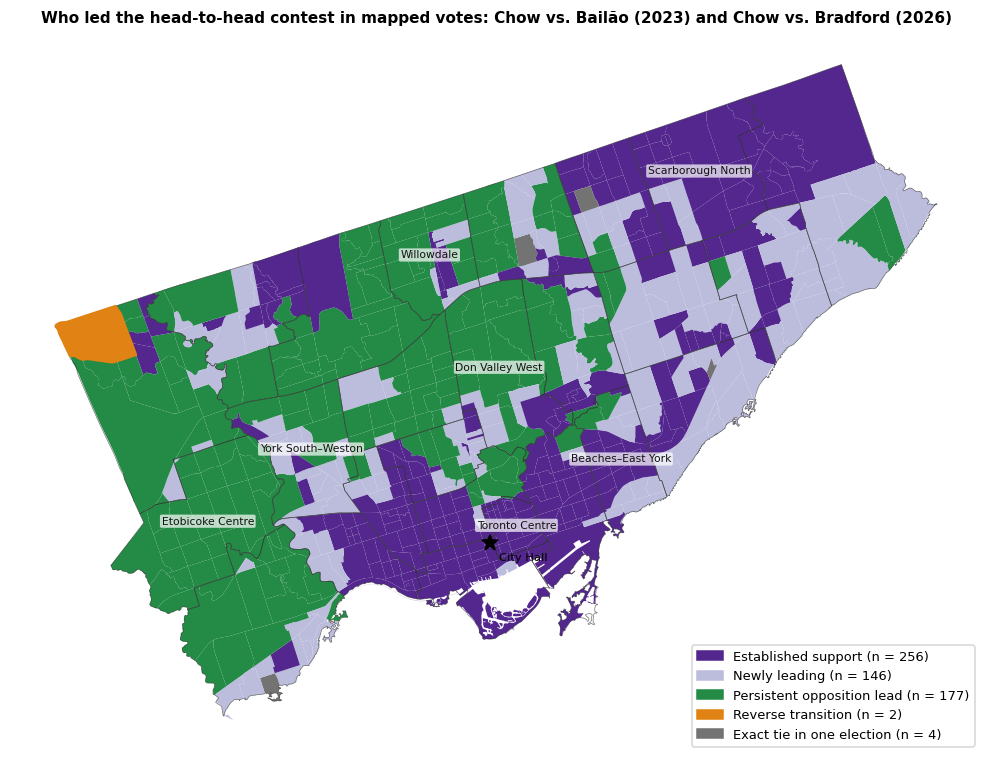

In [12]:
tp = t.to_crs(PROJECTED_EPSG); wp = wards.to_crs(PROJECTED_EPSG)
tp["code"] = pd.Categorical(tp.group, categories=ALL_GROUPS).codes
label_pts = wp[wp["ward"].isin(LABEL_WARDS)].copy(); label_pts["pt"] = label_pts.geometry.representative_point()
fig, ax = plt.subplots(figsize=(10.5, 7.2))
tp.plot(column="code", cmap=ListedColormap([GROUP_COLOURS[g] for g in ALL_GROUPS]), ax=ax, linewidth=0)
wp.boundary.plot(ax=ax, color="#333333", linewidth=.45, alpha=.7)
tp[tp.group == "Reverse transition"].boundary.plot(ax=ax, color=GROUP_COLOURS["Reverse transition"], linewidth=1.6)
for _, r in label_pts.iterrows():
    ax.annotate(r["ward_name"].replace("-", "–"), (r["pt"].x, r["pt"].y), fontsize=7, ha="center", color="#111", bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.7))
ax.plot(cp.x, cp.y, marker="*", color="k", ms=11, zorder=5); ax.annotate("City Hall", (cp.x, cp.y), xytext=(6, -12), textcoords="offset points", fontsize=7.5)
ax.set_axis_off(); ax.legend(handles=[Patch(color=GROUP_COLOURS[g], label=f"{g} (n = {int((t.group == g).sum())})") for g in ALL_GROUPS], loc="lower right", fontsize=8.5, frameon=True)
ax.set_title("Who led the head-to-head contest in mapped votes: Chow vs. Bailão (2023) and Chow vs. Bradford (2026)", fontsize=10)
plt.tight_layout(); plt.show()

**The map.** The established core (deep purple) is a compact block around City Hall and along the lakeshore, extending through the east end and into pockets of the north-east. The newly leading tracts (light purple) form a broad, irregular middle zone on the east side and in parts of the west, rather than a continuous ring around the core. The persistent-opposition tracts (green) are a large contiguous area from the western edge through the north-west into the centre-north. The two orange reverse-transition tracts and four grey exact-tie tracts are isolated and should not be read as patterns.

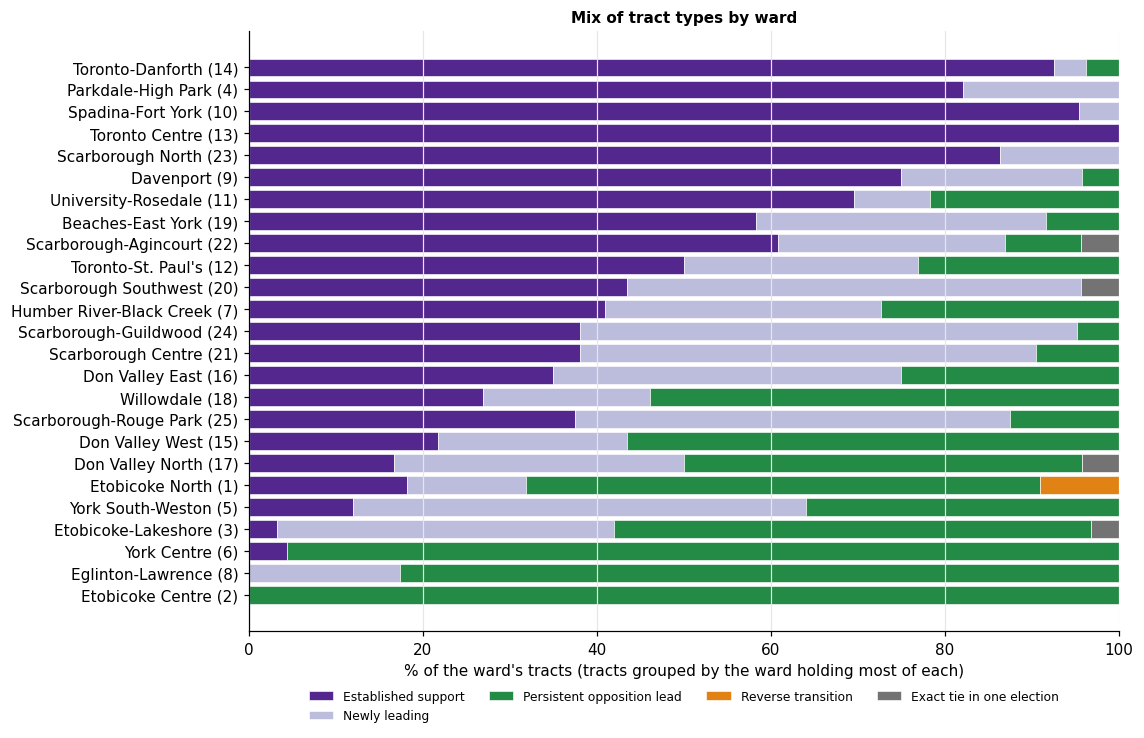

Wards with the highest share of newly leading tracts: {'Scarborough-Guildwood (12 of 21)': 57, 'Scarborough Centre (11 of 21)': 52, 'Scarborough Southwest (12 of 23)': 52, 'York South-Weston (13 of 25)': 52, 'Scarborough-Rouge Park (8 of 16)': 50, 'Don Valley East (8 of 20)': 40}
Wards holding the most persistent-opposition tracts: {'Etobicoke Centre (26 of 26)': None, 'York Centre (22 of 23)': None, 'Eglinton-Lawrence (19 of 23)': None, 'Etobicoke-Lakeshore (17 of 31)': None, 'Willowdale (14 of 26)': None, 'Don Valley West (13 of 23)': None}
Where the 146 newly leading tracts are, by ward (top 8): {'York South-Weston': 13, 'Etobicoke-Lakeshore': 12, 'Scarborough-Guildwood': 12, 'Scarborough Southwest': 12, 'Scarborough Centre': 11, 'Don Valley East': 8, 'Scarborough-Rouge Park': 8, 'Don Valley North': 8}


In [13]:
wc = pd.crosstab(t.ward_dominant, t.group).reindex(columns=ALL_GROUPS, fill_value=0).reindex(range(1, 26)).fillna(0)
wc["total"] = wc[ALL_GROUPS].sum(axis=1); wc["new_share"] = wc["Newly leading"] / wc.total * 100
order = wc.sort_values(["Established support", "Newly leading"], ascending=[True, True]).index
fig, ax = plt.subplots(figsize=(10.5, 6.8)); left = np.zeros(len(order))
labs = [f"{ward_names[w]} ({w})" for w in order]
for g in ALL_GROUPS:
    v = (wc.loc[order, g] / wc.loc[order, "total"] * 100).values; ax.barh(labs, v, left=left, color=GROUP_COLOURS[g], label=g, edgecolor="white", lw=.4); left += v
ax.set(xlabel="% of the ward's tracts (tracts grouped by the ward holding most of each)", title="Mix of tract types by ward"); ax.set_xlim(0, 100)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.08), ncol=4, frameon=False); ax.grid(False, axis="y"); plt.tight_layout(); plt.show()
top = wc.sort_values("new_share", ascending=False).head(6); print("Wards with the highest share of newly leading tracts:", {f"{ward_names[i]} ({int(r['Newly leading'])} of {int(r.total)})": round(r.new_share) for i, r in top.iterrows()})
print("Wards holding the most persistent-opposition tracts:", {f"{ward_names[i]} ({int(r['Persistent opposition lead'])} of {int(r.total)})": None for i, r in wc.sort_values('Persistent opposition lead', ascending=False).head(6).iterrows()})
print(f"Where the {int((t.group == 'Newly leading').sum())} newly leading tracts are, by ward (top 8):", {ward_names[i]: int(v) for i, v in wc["Newly leading"].sort_values(ascending=False).head(8).items()})

**Where the newly leading tracts are.** Around half of the tracts in **Scarborough-Guildwood (12 of 21), Scarborough Southwest (12 of 23), Scarborough Centre (11 of 21), York South-Weston (13 of 25) and Scarborough-Rouge Park (8 of 16)** are newly leading; Etobicoke-Lakeshore (12 tracts) and Don Valley East and North (8 each) also have many. The persistent-opposition tracts are concentrated in **Etobicoke Centre (26 of 26 tracts), York Centre (22 of 23), Eglinton-Lawrence (19 of 23), Etobicoke-Lakeshore (17 of 31), Willowdale (14 of 26) and Don Valley West (13 of 23)**. These ward groupings are tract groups by the ward holding most of each tract, not official ward results.

### 4.2 Distance from City Hall

Fixed 5 km bands using the verified distance field. Left and middle: Chow's margin and share of the pair, pooled, in 2023 and 2026. Right: the mix of tract types in each band. Distance is context for where support grew, not an explanation by itself.

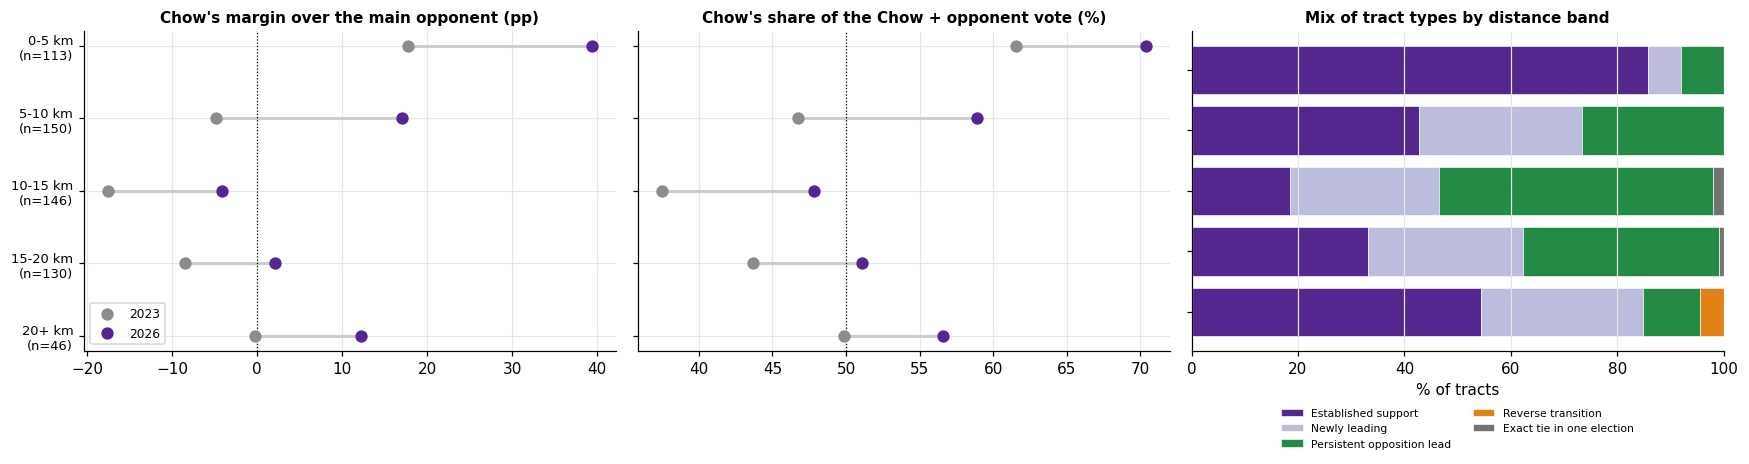

Pooled by distance band:


,tracts,margin23,margin26,pair23,pair26
0-5 km,113.00,17.80,39.40,61.60,70.40
5-10 km,150.00,-4.80,17.10,46.70,58.90
10-15 km,146.00,-17.60,-4.10,37.50,47.80
15-20 km,130.00,-8.50,2.00,43.60,51.10
20+ km,46.00,-0.20,12.20,49.80,56.60


Newly leading tracts by distance band: {'0-5 km': 7, '5-10 km': 46, '10-15 km': 41, '15-20 km': 38, '20+ km': 14}
Share of her additional mapped votes from each band (%): {'0-5 km': 26.0, '5-10 km': 29.0, '10-15 km': 20.0, '15-20 km': 17.0, '20+ km': 7.0}


In [14]:
t["band"] = pd.cut(t.dist__nc, DISTANCE_BANDS, labels=BAND_LABELS, right=False)
B = pd.DataFrame({b: pooled(t[t.band == b]) for b in BAND_LABELS}).T
comp = pd.crosstab(t.band, t.group, normalize="index").reindex(columns=ALL_GROUPS, fill_value=0) * 100
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4)); yb = np.arange(len(BAND_LABELS))[::-1]
for a, (c23, c26, ttl, ref) in zip(ax[:2], (("margin23", "margin26", "Chow's margin over the main opponent (pp)", 0), ("pair23", "pair26", "Chow's share of the Chow + opponent vote (%)", 50))):
    a.hlines(yb, B[c23], B[c26], color="#cccccc", lw=2); a.scatter(B[c23], yb, color=C23, s=50, zorder=3, label="2023"); a.scatter(B[c26], yb, color=CHOW, s=50, zorder=3, label="2026"); a.axvline(ref, color="k", ls=":", lw=.8)
    a.set(title=ttl); a.set_yticks(yb); a.set_yticklabels([f"{b}\n(n={int(B.loc[b, 'tracts'])})" for b in BAND_LABELS] if a is ax[0] else [], fontsize=8.5)
ax[0].legend(fontsize=8, loc="lower left"); left = np.zeros(len(BAND_LABELS))
for g in ALL_GROUPS:
    ax[2].barh(yb, comp[g].values, left=left, color=GROUP_COLOURS[g], label=g, edgecolor="white", lw=.4); left += comp[g].values
ax[2].set(title="Mix of tract types by distance band", xlabel="% of tracts"); ax[2].set_yticks(yb); ax[2].set_yticklabels([]); ax[2].set_xlim(0, 100); ax[2].grid(False, axis="y")
ax[2].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2, frameon=False); plt.tight_layout(); plt.show()
print("Pooled by distance band:"); display(B[["tracts", "margin23", "margin26", "pair23", "pair26"]].round(1))
print("Newly leading tracts by distance band:", {b: int(((t.band == b) & (t.group == "Newly leading")).sum()) for b in BAND_LABELS})
print("Share of her additional mapped votes from each band (%):", (B.add_chow / B.add_chow.sum() * 100).round(0).to_dict())

**Distance from City Hall.** Chow's pooled margin rose in every band (+22 points in the 0-5 km band, +22 in 5-10, +13.5 in 10-15, +10.5 in 15-20, +12.4 beyond 20 km) but only some bands flipped: the 5-10 km band moved from −4.8 to +17.1 and the 15-20 km band from −8.5 to +2.0; the 10-15 km band improved from −17.6 to −4.1 and remained negative. **The pattern is not monotonic**: the 20+ km band (46 tracts) leans more to Chow than 10-15 km. Newly leading tracts are spread over 5-20 km (46, 41 and 38 tracts in the three bands) with only 7 inside 5 km, where 86% of tracts were already established, and 14 beyond 20 km. The 0-10 km bands supplied 55% of her additional mapped votes and the 10-20 km bands 37%. So the newly leading areas begin at about 5 km and extend well past 10 km: a mid-to-outer-ring expansion, not a thin belt hugging the core.

### 4.3 Different directions

Tracts are placed by their bearing from City Hall (clockwise from north) and distance band. Each panel is one direction (the lake sits to the south and south-east, so few tracts fall there); lines show Chow's pooled margin by band in 2023 and 2026, and only bands with at least five tracts are drawn. Where the 2026 line crosses zero, Chow led the pair at that distance.

Tracts by direction from City Hall: {'Northeast': 166, 'Southwest-West': 139, 'North': 134, 'Northwest': 121, 'East': 19, 'Other': 6}


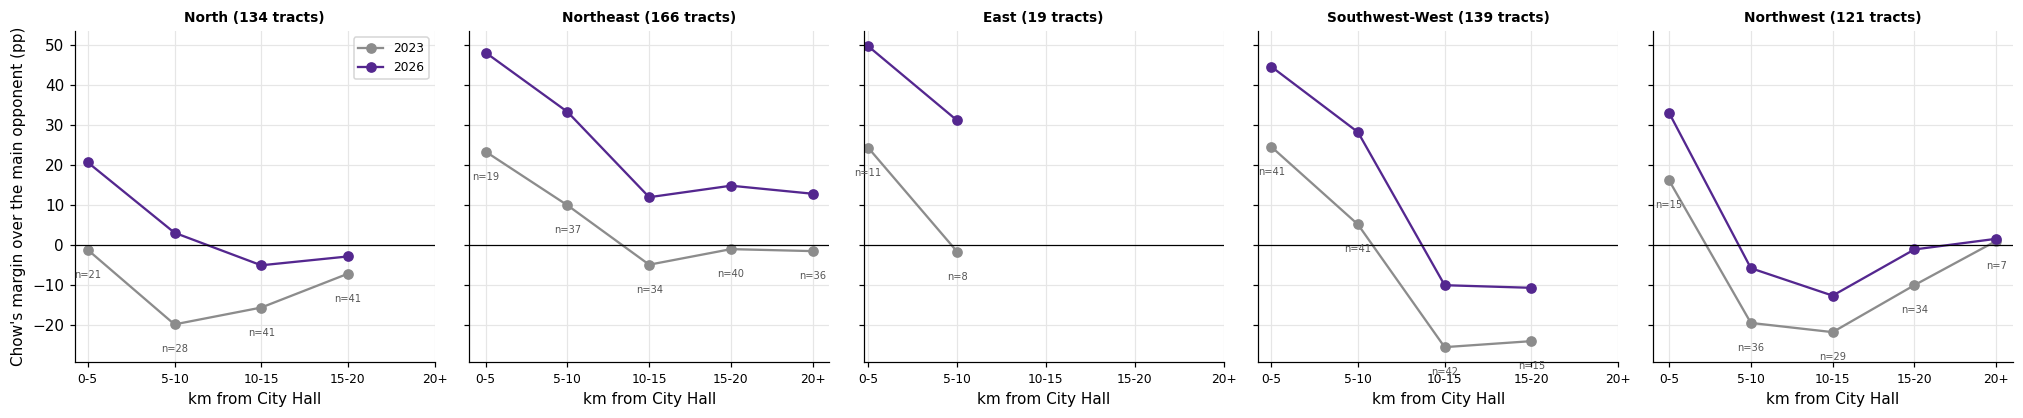

Chow's pooled margin, 2023 → 2026 (pp), by direction and distance band (blank = fewer than 5 tracts):


,0-5 km,5-10 km,10-15 km,15-20 km,20+ km
North,-1 → +21 (n=21),-20 → +3 (n=28),-16 → -5 (n=41),-7 → -3 (n=41),
Northeast,+23 → +48 (n=19),+10 → +33 (n=37),-5 → +12 (n=34),-1 → +15 (n=40),-1 → +13 (n=36)
East,+24 → +50 (n=11),-2 → +31 (n=8),,,
Southwest-West,+25 → +45 (n=41),+5 → +28 (n=41),-25 → -10 (n=42),-24 → -11 (n=15),
Northwest,+16 → +33 (n=15),-19 → -6 (n=36),-22 → -13 (n=29),-10 → -1 (n=34),+1 → +2 (n=7)


Tract-type mix by direction (% of tracts):


group,Established support,Newly leading,Persistent opposition lead,Reverse transition,Exact tie in one election
sector,,,,,
North,30.00,24.00,45.00,0.00,1.00
Northeast,60.00,34.00,6.00,0.00,1.00
East,68.00,32.00,0.00,0.00,0.00
Southwest-West,47.00,19.00,34.00,0.00,1.00
Northwest,28.00,21.00,50.00,2.00,0.00


In [15]:
bearing = (np.degrees(np.arctan2(t.dx, t.dy)) % 360)
def sector_of(b):
    for name, (lo, hi) in SECTORS.items():
        if (lo <= b < hi) if lo < hi else (b >= lo or b < hi): return name
    return "Other"
t["sector"] = bearing.map(sector_of)
print("Tracts by direction from City Hall:", t.sector.value_counts().to_dict())
sec = [s for s in SECTORS if (t.sector == s).sum() >= MIN_SECTOR_TRACTS]
fig, axes = plt.subplots(1, len(sec), figsize=(3.7 * len(sec), 3.9), sharey=True)
for a, s in zip(np.atleast_1d(axes), sec):
    d = t[t.sector == s]; rows = []
    for i, b in enumerate(BAND_LABELS):
        dd = d[d.band == b]
        if len(dd) >= 5: p = pooled(dd); rows.append((i, p.margin23, p.margin26, len(dd)))
    r = pd.DataFrame(rows, columns=["i", "m23", "m26", "n"])
    a.plot(r.i, r.m23, "o-", color=C23, label="2023"); a.plot(r.i, r.m26, "o-", color=CHOW, label="2026"); a.axhline(0, color="k", lw=.8)
    for _, q in r.iterrows(): a.text(q.i, min(q.m23, q.m26) - 7, f"n={int(q.n)}", ha="center", fontsize=6.5, color="#555")
    a.set_xticks(range(len(BAND_LABELS))); a.set_xticklabels([b.replace(" km", "") for b in BAND_LABELS], fontsize=8); a.set_title(f"{s} ({len(d)} tracts)", fontsize=9); a.set_xlabel("km from City Hall")
np.atleast_1d(axes)[0].set_ylabel("Chow's margin over the main opponent (pp)"); np.atleast_1d(axes)[0].legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()
grid = {}
for s_ in sec:
    for b in BAND_LABELS:
        dd = t[(t.sector == s_) & (t.band == b)]
        grid.setdefault(s_, {})[b] = f"{pooled(dd).margin23:+.0f} → {pooled(dd).margin26:+.0f} (n={len(dd)})" if len(dd) >= 5 else ""
print("Chow's pooled margin, 2023 → 2026 (pp), by direction and distance band (blank = fewer than 5 tracts):"); display(pd.DataFrame(grid).T)
print("Tract-type mix by direction (% of tracts):"); display((pd.crosstab(t.sector, t.group, normalize="index").reindex(columns=ALL_GROUPS, fill_value=0) * 100).loc[sec].round(0))

**Different directions.** The ring is not even. In the **north-east sector** the 2023 margin was near zero or negative beyond 10 km (−5 to −1) and by 2026 was +12 to +15 in every band beyond it, so 94% of its tracts are Chow-led (60% established, 34% newly leading, 6% persistent opposition). In the **south-west/west** and **north-west** sectors the margin also rose at every distance, but beyond 10 km it stayed negative (south-west/west −25 → −10 at 10-15 km; north-west −22 → −13), leaving 34% and 50% of those sectors in persistent opposition; the **north** is in between (45% persistent opposition; −16 → −5 at 10-15 km). Expansion therefore ran furthest outward on the east side and stopped short toward the west and north-west, where Chow's improvement of roughly 9-15 points was not enough to overcome the main opponent. Each sector is only a bearing from City Hall, not a named neighbourhood.

## 5. Changing support or changing composition?

Did Chow become more competitive in particular *kinds* of neighbourhood (her share within each group), and did those kinds of neighbourhood account for a different share of her mapped votes (the group's share of her votes)? These are different questions. Groups are fixed census-based **quintiles**, the same in both years: renter share, car commuting and income rank. The grey markers show each group's share of **all** valid mapped votes, because a group can supply more of her votes simply because more votes were cast there.

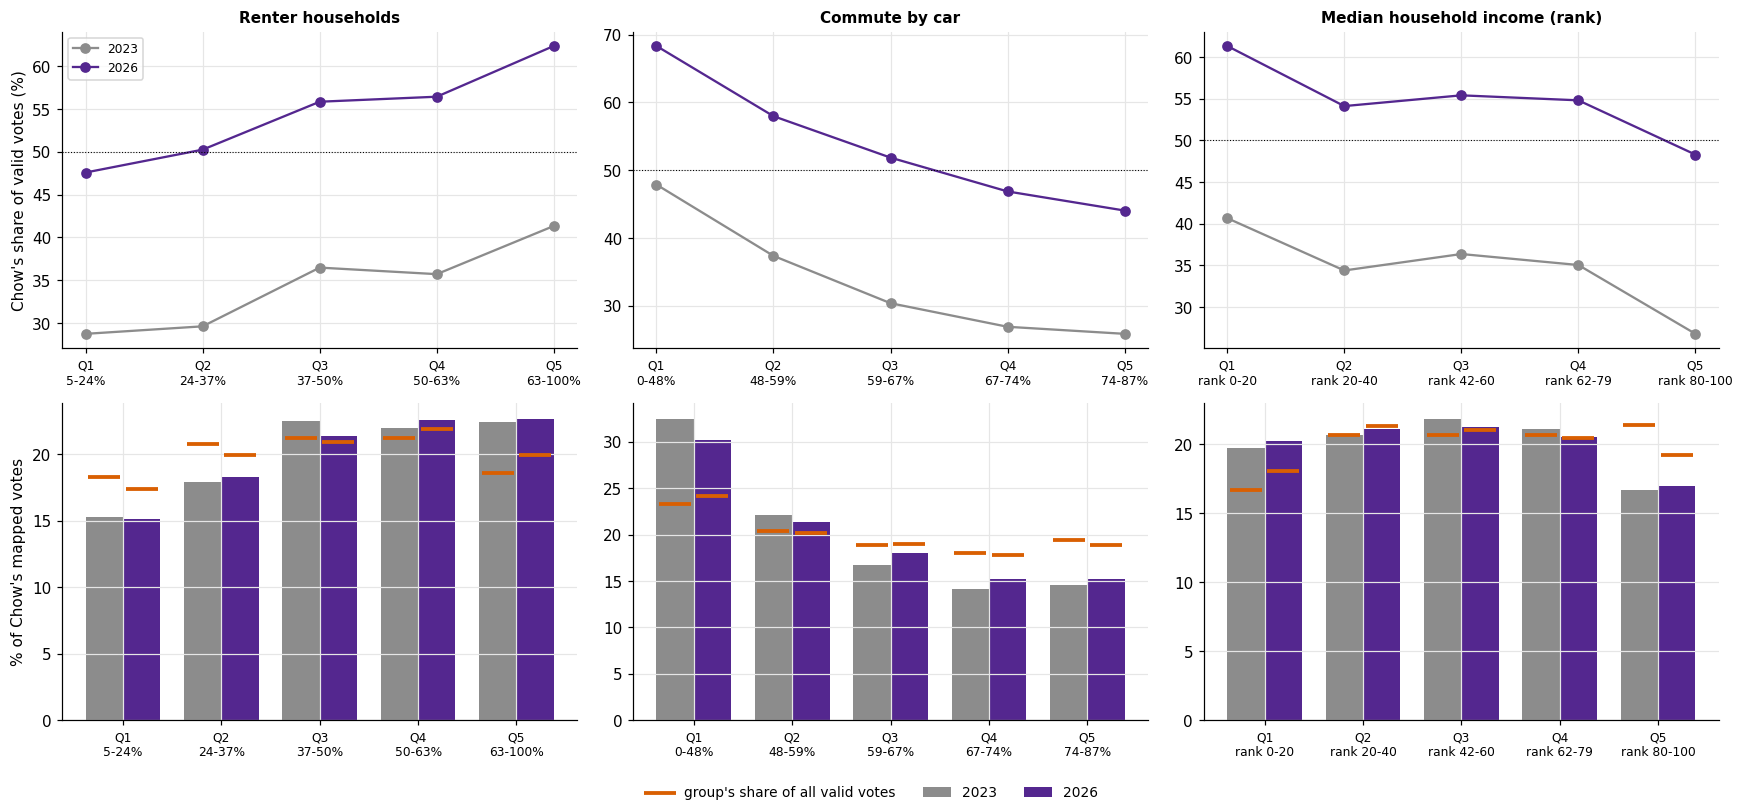

,top-two quintiles' share of Chow's votes 2023,2026,bottom-two quintiles' share 2023,bottom-two 2026,"Chow share gap, Q5 minus Q1, 2023 (pp)",gap 2026 (pp)
dimension,,,,,,
Renter households,44.40,45.30,33.10,33.40,12.60,14.80
Commute by car,28.70,30.40,54.60,51.60,-22.00,-24.30
Median household income (rank),37.70,37.50,40.40,41.30,-13.90,-13.00


In [16]:
QV = {"hhtnrent_pct": ("Renter households", lambda v: f"{v * 100:.0f}%"), "jwmdauto_pct": ("Commute by car", lambda v: f"{v * 100:.0f}%"), "ihat_med__nc": ("Median household income (rank)", None)}
rows = []; fig, axes = plt.subplots(2, 3, figsize=(16, 7.4))
for j, (col, (nm, fmt)) in enumerate(QV.items()):
    d = t.dropna(subset=[col]).copy(); d["q"] = pd.qcut(d[col], 5, labels=False) + 1
    q = pd.DataFrame({k: pooled(g) for k, g in d.groupby("q")}).T
    q["chow_of_chow23"], q["chow_of_chow26"] = q.chow_v23 / q.chow_v23.sum() * 100, q.chow_v26 / q.chow_v26.sum() * 100
    q["valid_of_all23"], q["valid_of_all26"] = q.valid23 / q.valid23.sum() * 100, q.valid26 / q.valid26.sum() * 100
    rng_ = d.groupby("q")[col].agg(["min", "max"]); tick = [f"Q{k}\n" + (f"{rng_.loc[k, 'min'] * 100:.0f}-{rng_.loc[k, 'max'] * 100:.0f}%" if fmt else f"rank {int(d.groupby('q').income_rank.min()[k])}-{int(d.groupby('q').income_rank.max()[k])}") for k in range(1, 6)]
    a = axes[0, j]; a.plot(q.index, q.chow23, "o-", color=C23, label="2023"); a.plot(q.index, q.chow26, "o-", color=CHOW, label="2026"); a.axhline(50, color="k", ls=":", lw=.7)
    a.set_title(nm); a.set_xticks(q.index); a.set_xticklabels(tick, fontsize=8); axes[0, 0].set_ylabel("Chow's share of valid votes (%)")
    a = axes[1, j]; w = .38
    a.bar(q.index - w / 2, q.chow_of_chow23, width=w, color=C23, label="2023"); a.bar(q.index + w / 2, q.chow_of_chow26, width=w, color=CHOW, label="2026")
    a.scatter(q.index - w / 2, q.valid_of_all23, color="#d95f02", marker="_", s=420, linewidths=2.5, zorder=4, label="group's share of all valid votes"); a.scatter(q.index + w / 2, q.valid_of_all26, color="#d95f02", marker="_", s=420, linewidths=2.5, zorder=4)
    a.set_xticks(q.index); a.set_xticklabels(tick, fontsize=8); axes[1, 0].set_ylabel("% of Chow's mapped votes")
    rows.append({"dimension": nm, "top-two quintiles' share of Chow's votes 2023": q.chow_of_chow23.iloc[3:].sum(), "2026": q.chow_of_chow26.iloc[3:].sum(),
                 "bottom-two quintiles' share 2023": q.chow_of_chow23.iloc[:2].sum(), "bottom-two 2026": q.chow_of_chow26.iloc[:2].sum(),
                 "Chow share gap, Q5 minus Q1, 2023 (pp)": q.chow23.iloc[-1] - q.chow23.iloc[0], "gap 2026 (pp)": q.chow26.iloc[-1] - q.chow26.iloc[0]})
axes[0, 0].legend(fontsize=8)
h, l = axes[1, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9); plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()
display(pd.DataFrame(rows).set_index("dimension").round(1))

**Was it new places or the same places, more?** Chow's share rose in every fifth of every dimension (top row), and the gradient stayed: she was strongest in the most renter-heavy tracts (Q5 − Q1 gap in share: 12.6 points in 2023, 14.8 in 2026), the least car-oriented (−22.0 → −24.3) and the lowest-income tracts (−13.9 → −13.0). The bottom row shows where her votes came from. By **renters** and **income** the distribution of her mapped votes is almost unchanged (the two most renter-heavy fifths supplied 44.4% of her votes in 2023 and 45.3% in 2026). By **car commuting** there is a modest drift outward: the two most car-oriented fifths supplied 28.7% of her votes in 2023 and 30.4% in 2026, the two least car-oriented 54.6% and 51.6%. Orange markers show each group's share of all valid votes; Chow's votes over-represent the least car-oriented and most renter-heavy groups relative to their share of all votes in both years. Because more votes were cast everywhere, a group's share of her votes can move because of volume as well as preference, so these are small shifts: the geographic base broadened a little toward car-oriented areas without changing the underlying gradients.

## 6. Editorial assessment

### What the evidence says about "core-plus"

The evidence supports a **qualified** version of core-plus. The core was strengthened and extended, but not as a concentric ring.

- **Her established base** is a compact set of 256 tracts, a median 6.6 km from City Hall, typically renter-heavy (51% of households), almost without single-detached housing (7%), with comparatively few car commuters (52%), many who walk or cycle (12%) and lower-ranked incomes (rank 37 of 100).
- **The added neighbourhoods** (146 tracts) are intermediate in housing, tenure, income and age (renters 40%, single-detached 29%, income rank 50), close to the persistent-opposition areas in car commuting (66%), walking/cycling (4.3%) and distance (12.4 km), and different from both in lower university education (32%) and higher immigrant (49%) and visible-minority (58%) shares.
- **Where they are:** a broad middle zone, 5-20 km out, with the highest concentrations in Scarborough-Guildwood, Scarborough Southwest, Scarborough Centre, Scarborough-Rouge Park and York South-Weston; expansion ran furthest on the east side.
- **Did the coalition broaden or intensify?** Both, modestly. Half of her additional votes (50.5%) were in established-support tracts, a quarter (26.7%) in newly leading ones and a fifth (22.2%) in places where she still trailed; the established base's part of her mapped votes fell from 57% to 54%, and the most car-oriented fifths' part rose from 28.7% to 30.4%. The underlying gradients by tenure and car use did not narrow.
- **Where expansion remained limited:** the persistent-opposition tracts (177, 30% of the city's tracts) are the highest-income (rank 70), most detached-housing (46%), most car-oriented (72%) areas, concentrated in Etobicoke Centre, York Centre, Eglinton-Lawrence, Etobicoke-Lakeshore, Willowdale and Don Valley West. Chow gained about 18 points there but remained 17 points behind.

### Findings

1. **Half of her additional mapped votes came in tracts she already led** (108,917 of 215,705), a quarter (57,525) in the 146 she newly led, and a fifth (47,869) in the 177 where she still trailed.
2. **The newly leading tracts are not a ring next to the core.** Median distance from City Hall is 12.4 km, essentially the same as the persistent-opposition tracts (12.7 km) and almost twice the established base (6.6 km); only 7 of the 146 are within 5 km.
3. **They are intermediate on housing and income, but car-oriented.** Median single-detached share 29% (core 7%, opposition 46%), income rank 50 (37 and 70), but car commuting 66% (52% and 72%) and walking/cycling 4.3% (12.4% and 3.9%).
4. **Expansion was uneven by direction.** In the north-east sector 94% of tracts are Chow-led by 2026 (margin +12 to +15 beyond 10 km, from about −5 to −1); in the north-west sector 50% of tracts are persistent opposition.
5. **The divides persisted.** Her share gap between the most and least renter-heavy fifths was 12.6 points in 2023 and 14.8 in 2026; between the least and most car-oriented fifths, 22.0 and 24.3.
6. **Within the pair, gains were largest in the newly leading tracts** (median change in pair share +11.4 points vs. +6.9 in established-support tracts and +9.8 in persistent-opposition tracts), so the pattern is not only the contraction of the candidate field.

### Recommended graphics

1. **The transition map** (§4.1): the clearest single picture of where the base grew and where it did not.
2. **The distribution comparison of established, newly leading and persistent-opposition tracts** (§3), trimmed to four to six panels for the blog (renters, single-detached housing, car commuting, walking/cycling, income rank and distance). If space allows only one compact chart for the second slot, the **"between" dumbbell chart** (§3.1, left panel) states the finding ("intermediate on housing and income, close to the opposition areas on car use and distance") in one view and is the better choice; the eight-panel version is better for showing how much the groups overlap.

**Suggested captions.**
- *Map:* "Neighbourhoods by who led the head-to-head contest in mapped poll votes. Deep purple: Chow led in both 2023 (vs. Bailão) and 2026 (vs. Bradford). Light purple: Chow trailed in 2023 and led in 2026. Green: her main opponent led both times. Votes are estimated from polling-subdivision results and exclude advance and other ballots."
- *Distributions:* "Characteristics of the three groups of census tracts (each dot is a tract; the large marker is the median and the bar the middle half). Newly leading tracts fall between the established and persistent-opposition areas on housing and income, but resemble the opposition areas in car commuting and distance from City Hall. Census data are from 2021."

### Provisional "Growing the pie" text (about 200 words)

The tract-level results support part of that story, but the “plus” did not spread evenly outwards. Among mapped poll votes, Chow already led the head-to-head contest in 256 of 585 tracts in 2023. These were typically renter-heavy neighbourhoods about seven kilometres from City Hall, and she deepened that base: it supplied half of her additional votes. A further 146 tracts moved from trailing to leading, but they are not a ring hugging the core. They sit a median 12 kilometres out, as far as the areas where Bradford held on, and they resemble those areas in car commuting (66 per cent of commuters) and in how few people walk or cycle to work. On housing and income they fall between the two camps: more detached homes than the core (29 versus 7 per cent), but fewer than Bradford’s strongholds (46 per cent). They cluster in Scarborough and in York South–Weston. The limit was the west and north-west. There, 177 tracts, concentrated in Etobicoke Centre, York Centre and Eglinton–Lawrence, saw Chow gain about 18 points of vote share yet still trail. Her geographic base broadened modestly, but the divides by tenure and car use were at least as wide in 2026 as in 2023.

(It is written to follow the section's existing opening sentence.)

### Qualification

All tract figures describe **mapped poll votes** (78% of valid votes in 2023, 76% in 2026) and are estimates produced by allocating polling-subdivision results to census tracts; advance and other ballots, which favoured Chow strongly in 2023, are not in them, so "newly leading" refers to her position among mapped votes. Census characteristics (2021) describe the *neighbourhoods*, not the people who voted, and the same characteristics apply to both elections; the notebook shows where support grew across types of neighbourhood, and cannot show who the added voters were, whether any voter changed their choice, or the demographic composition of Chow's actual voters.